# Q3 Time Series Forecasting: Cumulative GitHub Stars

In [21]:
import numpy as np
import os

## 3.1 Dataset Description

In [22]:
DATA_DIR = '../data/Q3'
OUTPUT_DIR='./output'
DATA_FILE = f'{DATA_DIR}/stars_data.csv'
METADATA_FILE= f'{DATA_DIR}/repo metadata.json'
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

## 3.2 Single Repository Evaluation:

### 3.2.1 Preprocessing and Feature Engineering

In [23]:
from prep_stars import load_and_clean_data, normalize_data, plot_star_progression
from split_repos import split_repo_data, create_supervised_pairs


In [24]:
LOOKBACK = 21                 # Lookback window (p) for DL models 
ARMA_ORDER = (5, 0, 2)        # ARIMA order (p, d, q) 
DL_EPOCHS = 50
DL_PATIENCE = 10
DL_HIDDEN_SIZE = 64
RNN_L=2                     # Number of RNN layers
REPO_IDS = ['facebook/react', 'pallets/flask']
REPO_ID_COLUMN_CANDIDATES = ['repo_id', 'repository_id', 'id']

### 3.2.2 Forecasting Models

In [25]:
from classical import fit_arma_model
from dl_models import RNNForecaster, CNNForecaster
from train_models import train_dl_model
from sklearn.preprocessing import StandardScaler

### 3.2.3 Evaluation Protocol

In [26]:
from evaluate import (
    evaluate_models, 
    plot_error_vs_horizon_chart, 
    plot_representative_forecast, 
    generate_summary_table,
    plot_single_metrics,
    plot_single_step_forecast,
    plot_single_step_residuals
)

<--- Q3: Time Series Forecasting for GitHub Stars --->

[STEP 1/5] Loading and Cleaning Data...
Repo facebook/react: Data truncated at 2014-02-12 due to 250 days of stagnation.
Repo facebook/react: Final length: 260 days.
Repo pallets/flask: Data truncated at 2012-12-15 due to 250 days of stagnation.
Repo pallets/flask: Final length: 985 days.

 Processing Repository: facebook/react 


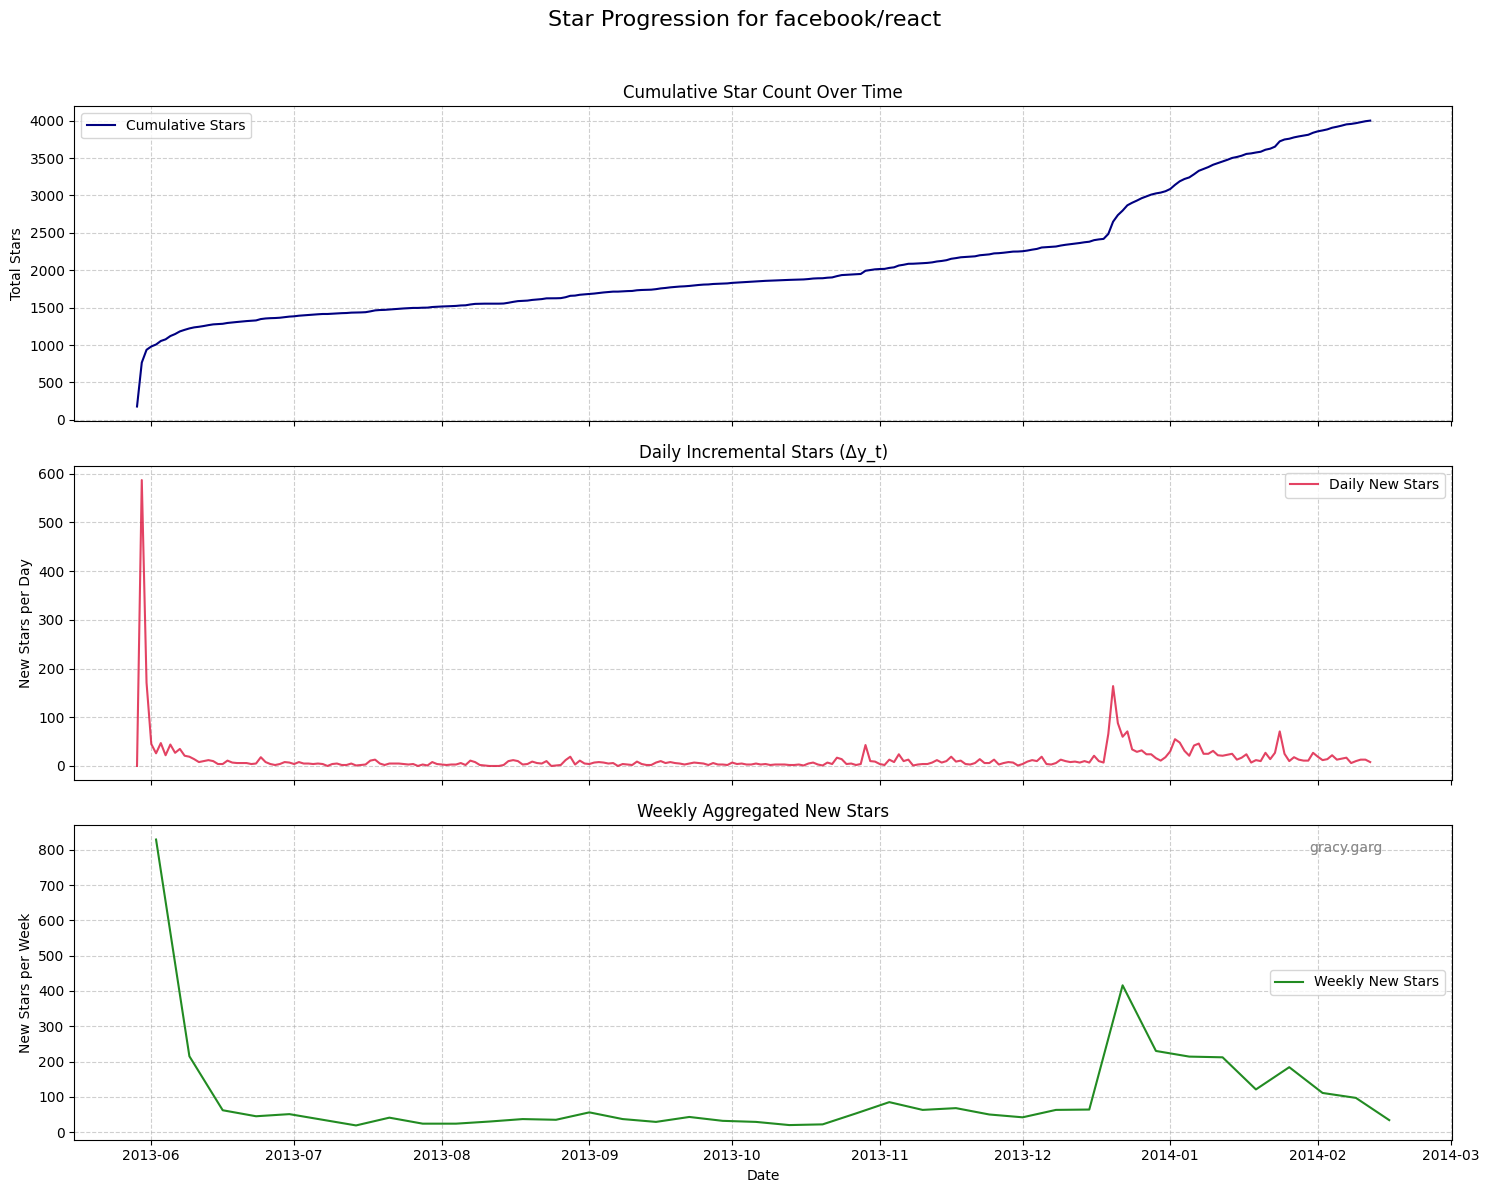

  -> Saved star progression plot to ./output/facebook_react_star_progression.png
[STEP 2/5] Training ARMA Model...
[STEP 3/5] Training RNN Forecaster...

Starting training for RNN...


.venv/lib64/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
.venv/lib64/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Epoch 10/50 | Train MSE: 0.014243 | Val MSE: 0.745548
Early stopping triggered for RNN at epoch 12.
[STEP 4/5] Training 1D CNN Forecaster...

Starting training for CNN...
Epoch 10/50 | Train MSE: 0.013972 | Val MSE: 0.791291
Early stopping triggered for CNN at epoch 13.
[STEP 5/5] Running Evaluation Protocol...

Single-Step Forecast Plot for facebook/react
Test set size: 31
Displaying first 31 predictions
Ground truth range: [6.00, 71.00]

ARMA:
  Prediction range: [10.40, 14.56]
  MAE: 6.869 | RMSE: 12.383

RNN:
  Prediction range: [7.11, 8.75]
  MAE: 10.136 | RMSE: 15.240

CNN:
  Prediction range: [4.94, 8.84]
  MAE: 10.869 | RMSE: 15.800


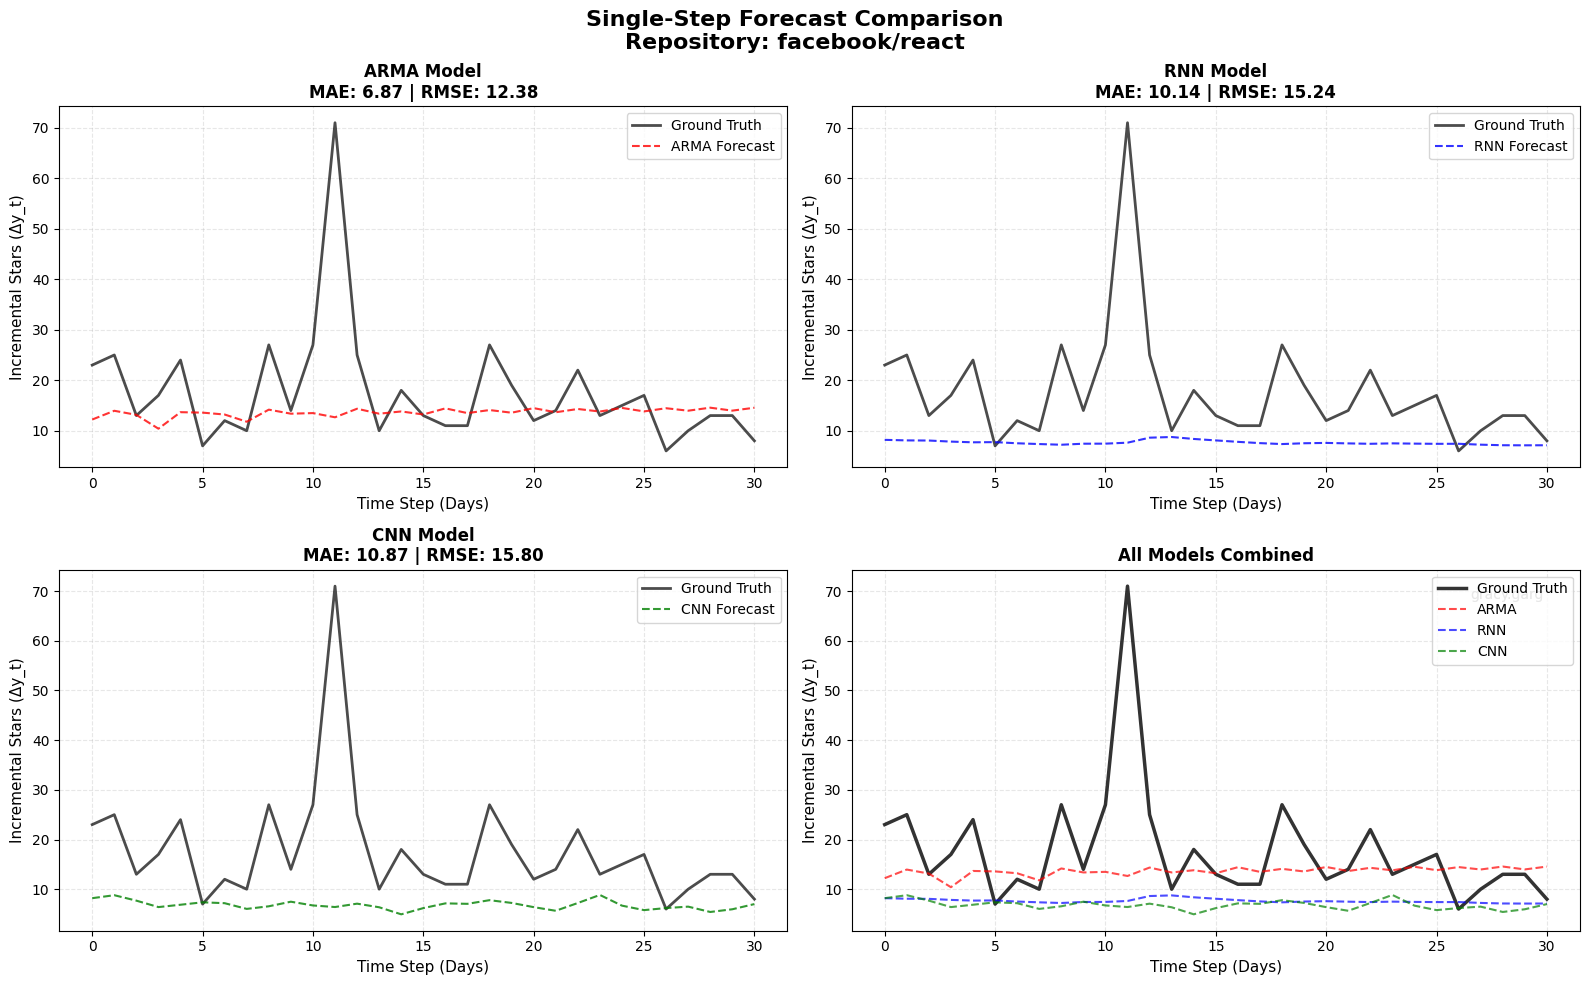


✓ Saved single-step forecast plot to: ./output/facebook_react_single_step_forecast.png



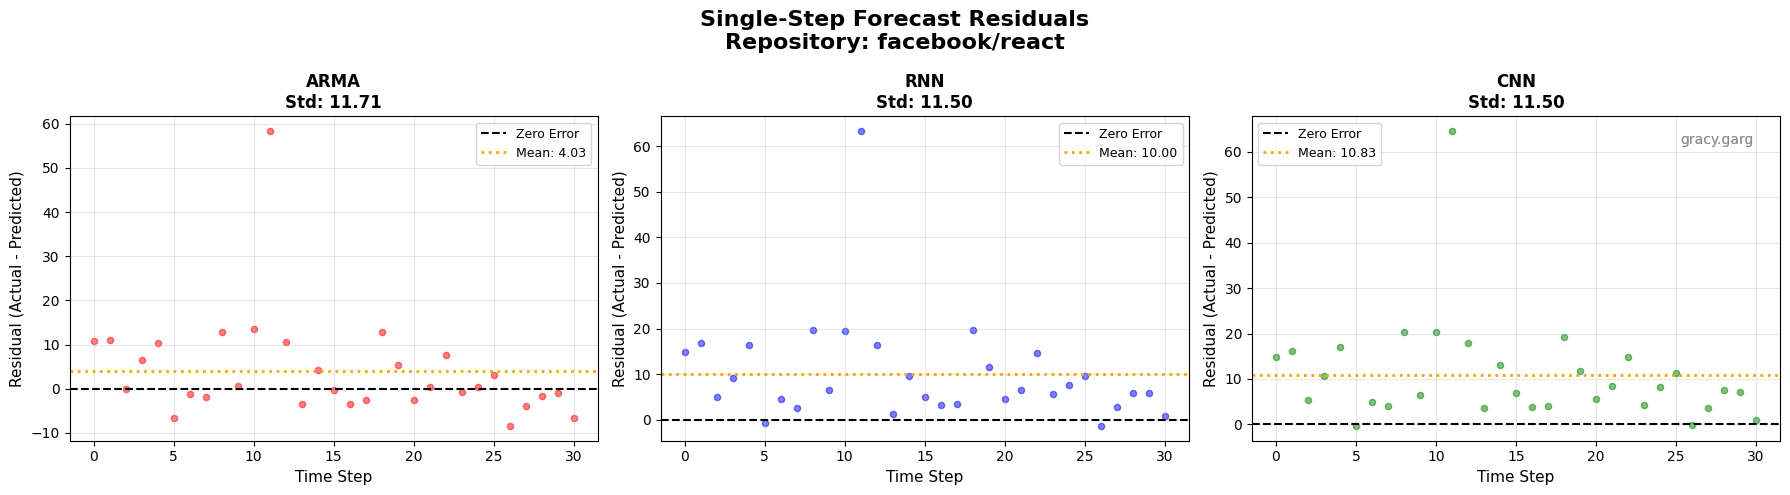

✓ Saved residual plot to: ./output/facebook_react_residuals.png


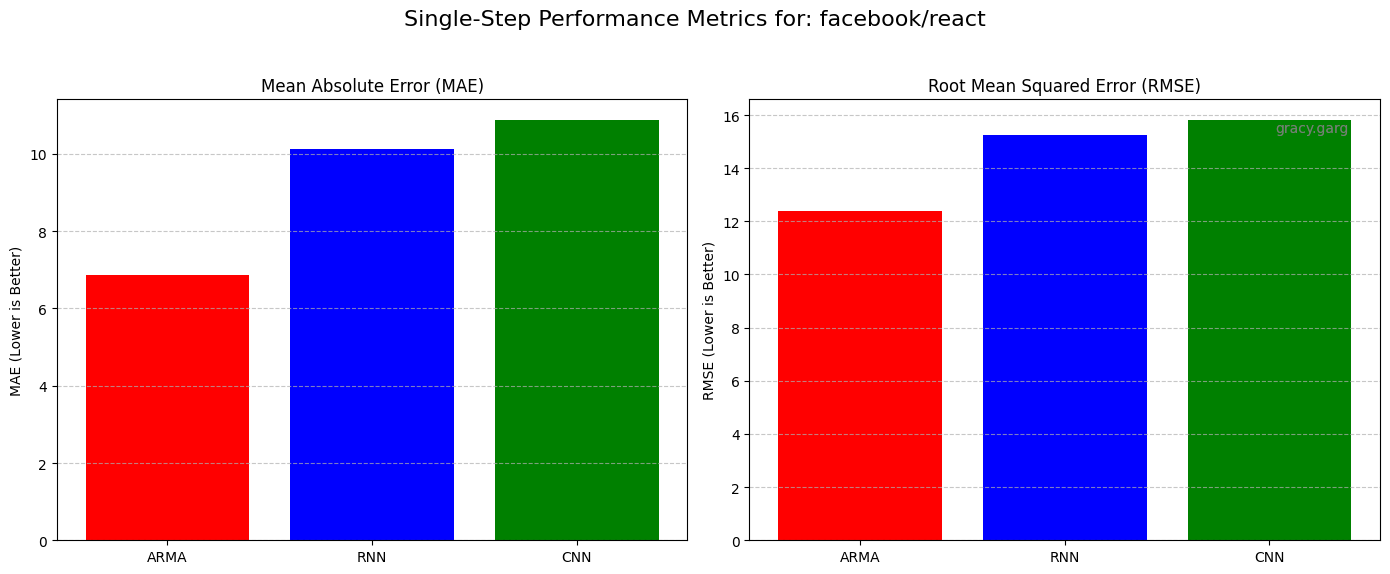

Saved single-repo metrics plot to ./output/single_metrics_facebook_react.png


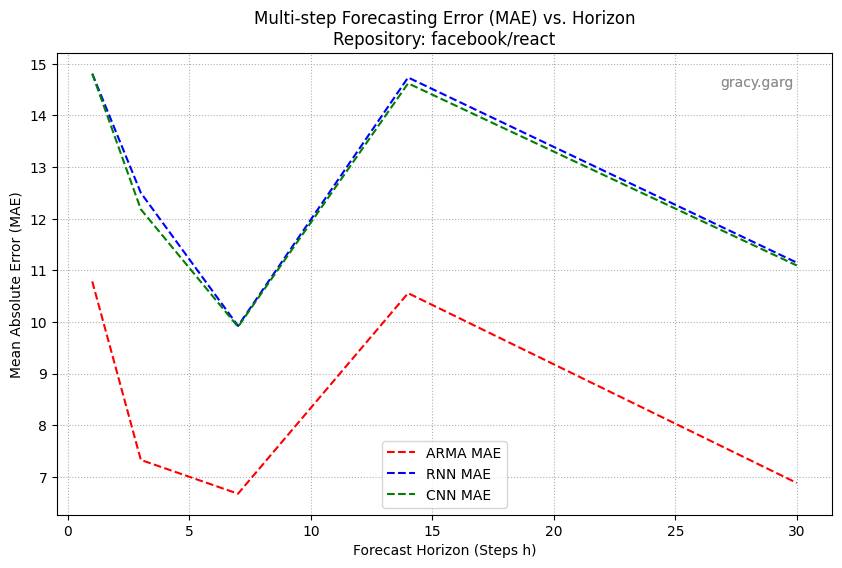

Saved stability plot to ./output/forecast_horizon_repo_facebook_react.png


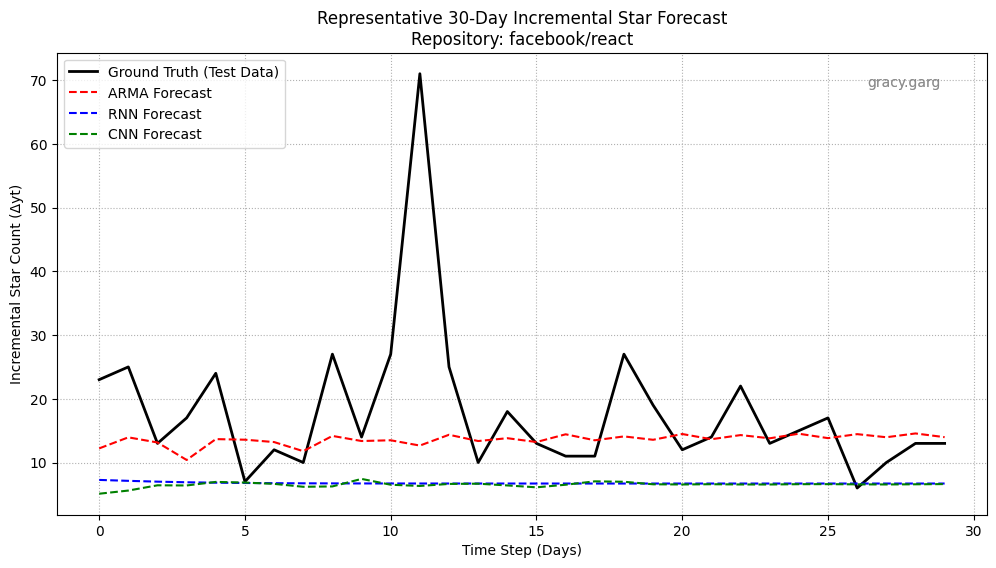

Saved representative forecast plot to ./output/representative_forecast_repo_facebook_react.png

 Processing Repository: pallets/flask 


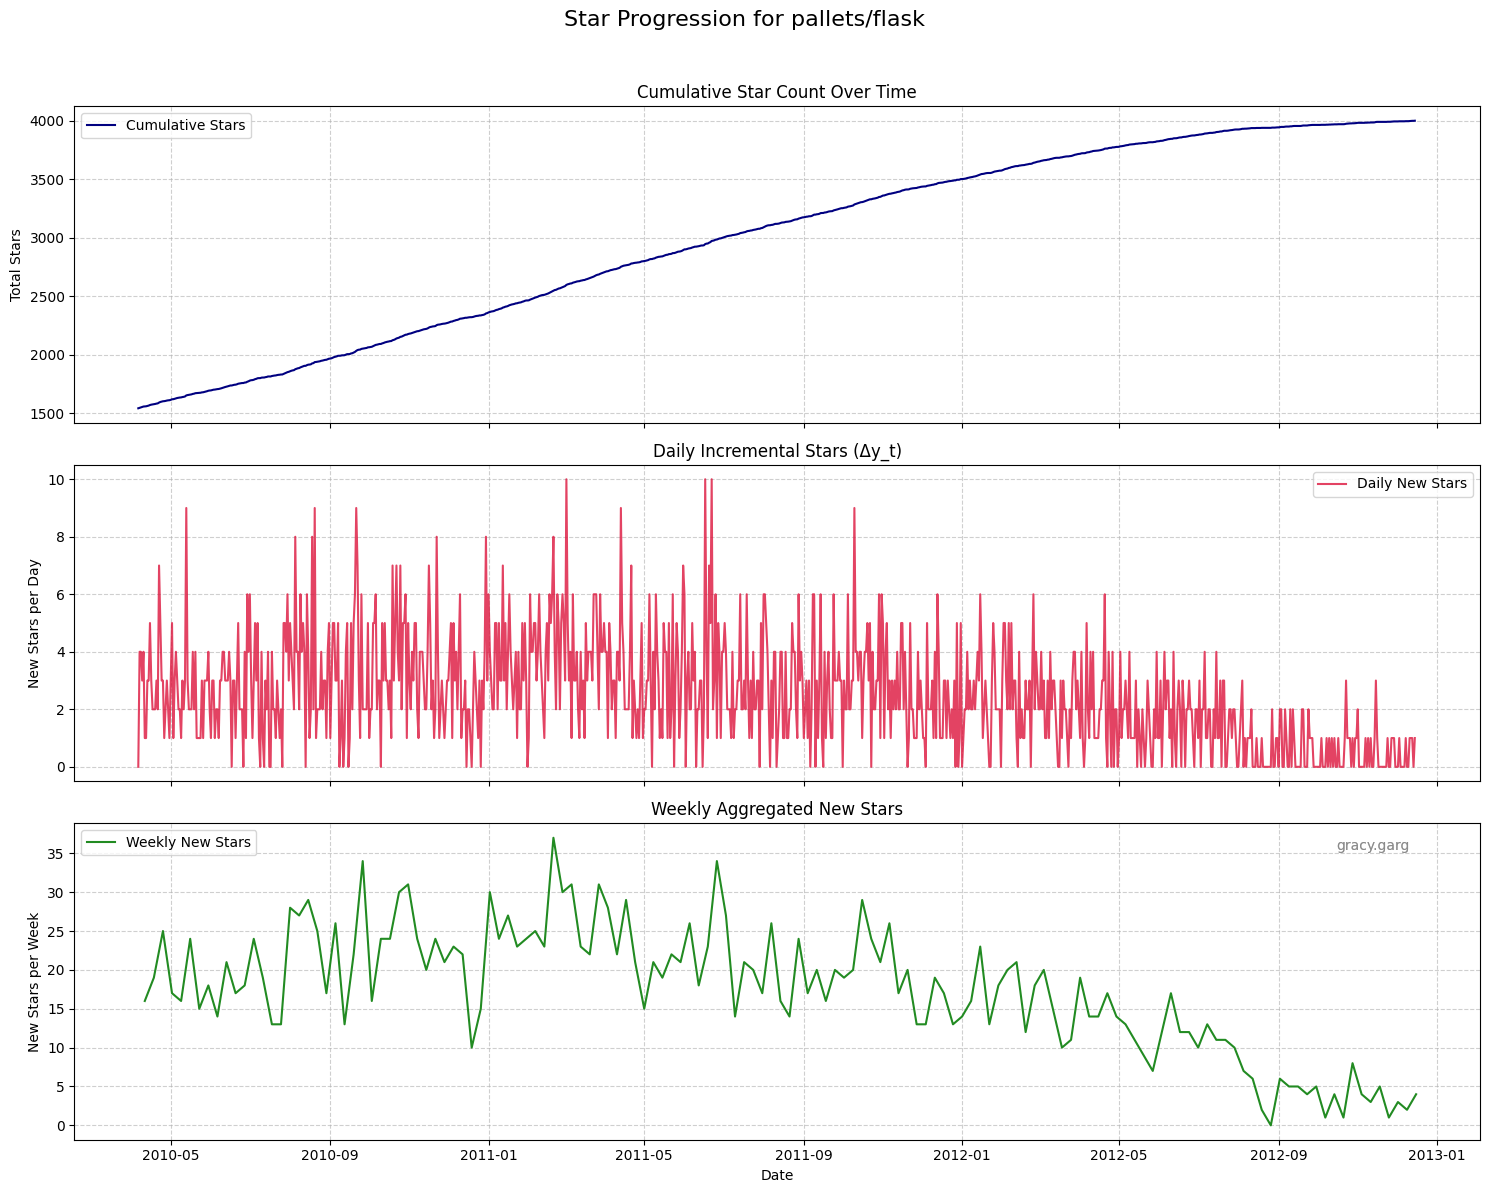

  -> Saved star progression plot to ./output/pallets_flask_star_progression.png
[STEP 2/5] Training ARMA Model...


.venv/lib64/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
.venv/lib64/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


[STEP 3/5] Training RNN Forecaster...

Starting training for RNN...
Epoch 10/50 | Train MSE: 0.981437 | Val MSE: 0.759529
Early stopping triggered for RNN at epoch 15.
[STEP 4/5] Training 1D CNN Forecaster...

Starting training for CNN...
Epoch 10/50 | Train MSE: 0.854797 | Val MSE: 0.750837
Early stopping triggered for CNN at epoch 11.
[STEP 5/5] Running Evaluation Protocol...

Single-Step Forecast Plot for pallets/flask
Test set size: 176
Displaying first 100 predictions
Ground truth range: [0.00, 4.00]

ARMA:
  Prediction range: [0.50, 0.81]
  MAE: 0.928 | RMSE: 1.125

RNN:
  Prediction range: [2.40, 2.79]
  MAE: 1.685 | RMSE: 1.894

CNN:
  Prediction range: [2.19, 2.79]
  MAE: 1.572 | RMSE: 1.784


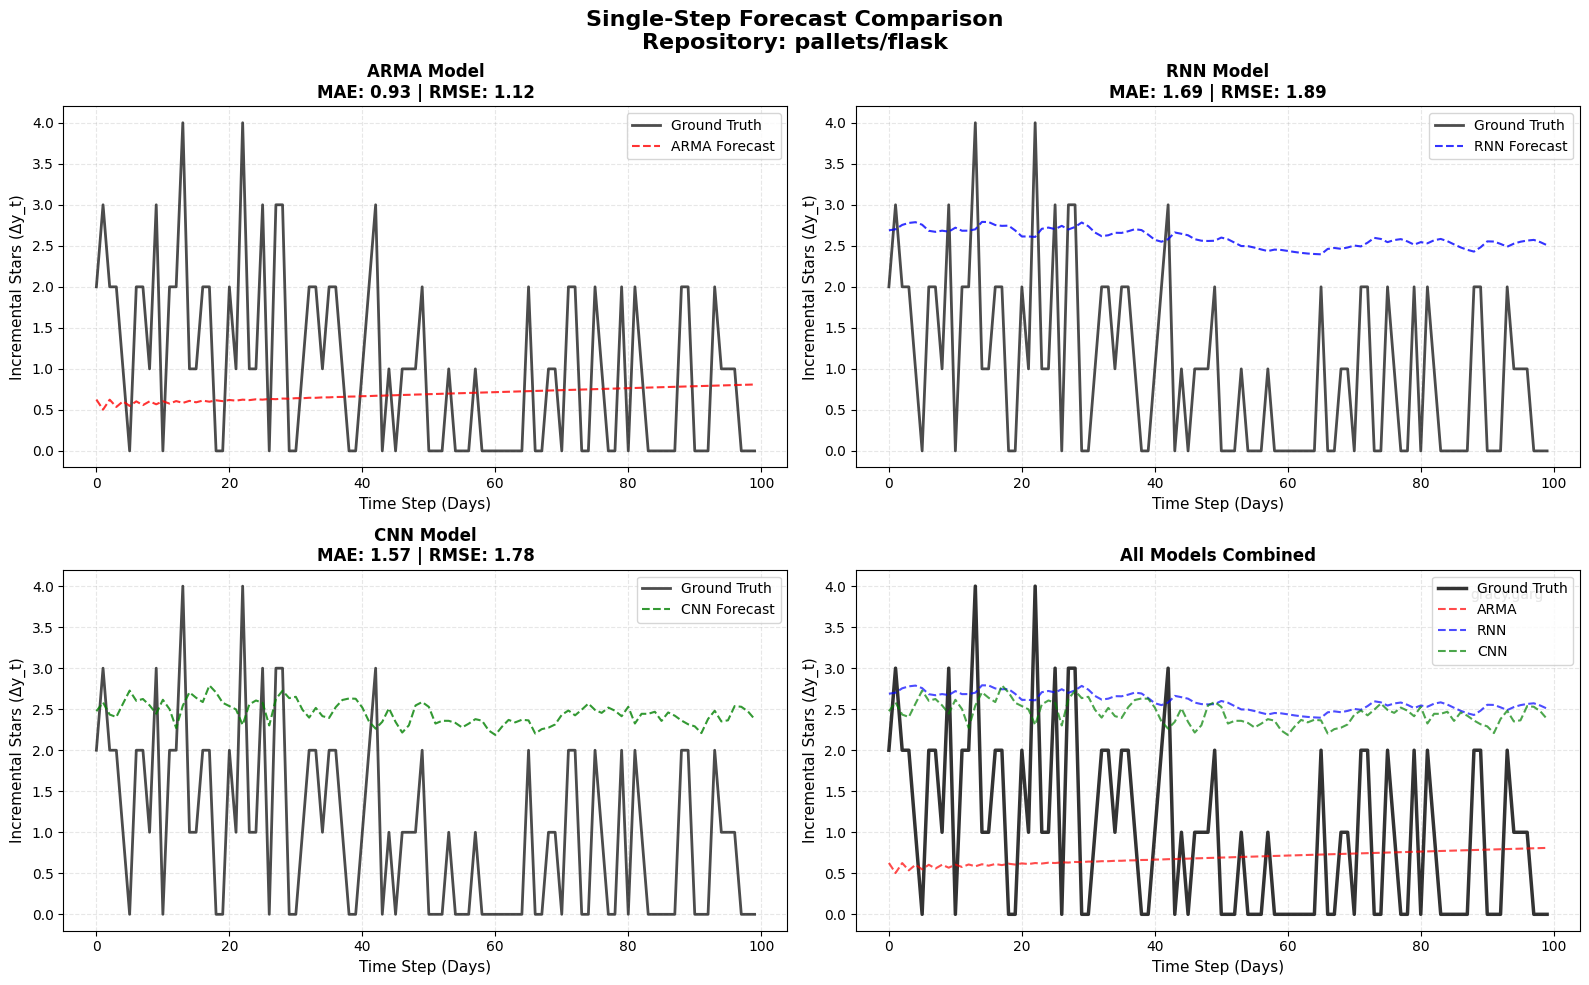


✓ Saved single-step forecast plot to: ./output/pallets_flask_single_step_forecast.png



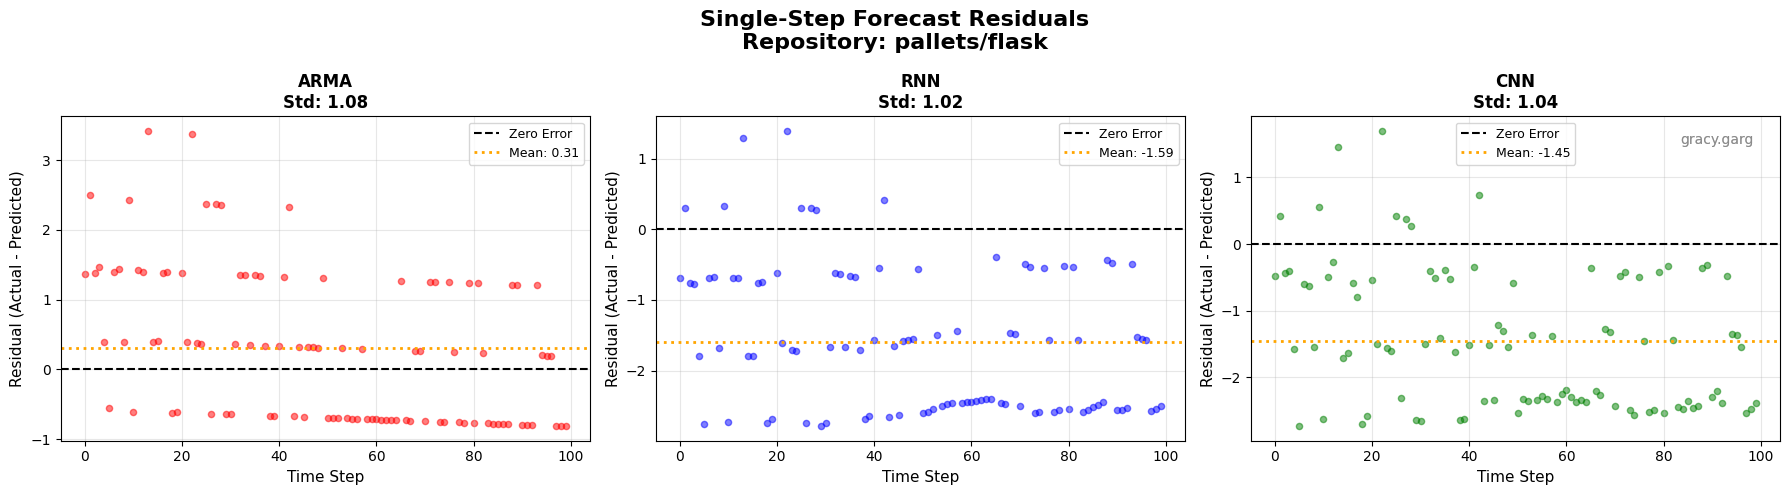

✓ Saved residual plot to: ./output/pallets_flask_residuals.png


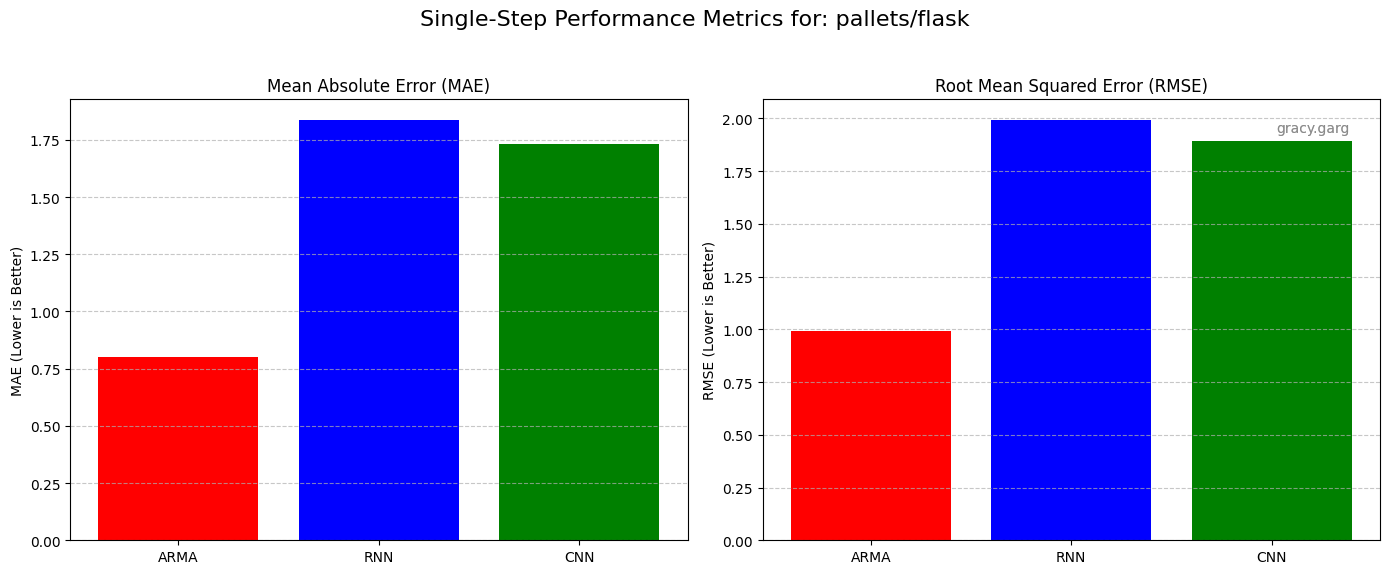

Saved single-repo metrics plot to ./output/single_metrics_pallets_flask.png


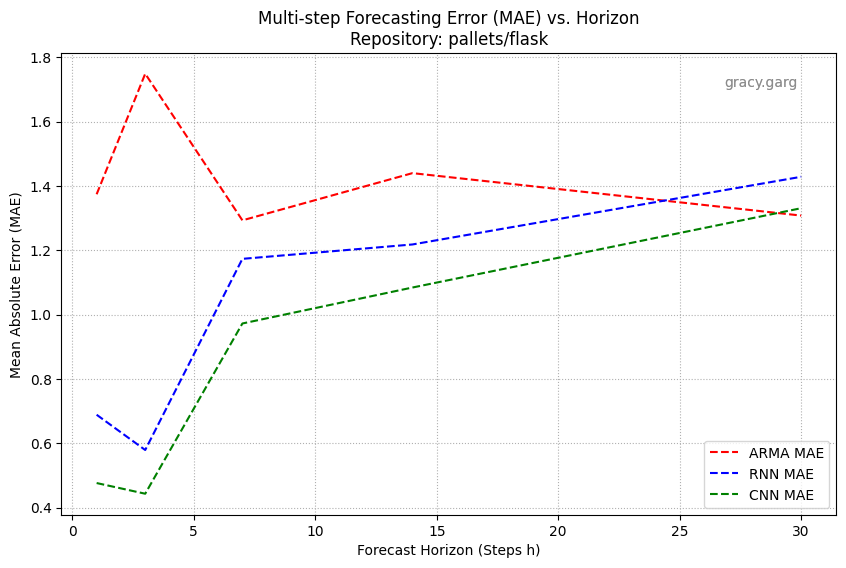

Saved stability plot to ./output/forecast_horizon_repo_pallets_flask.png


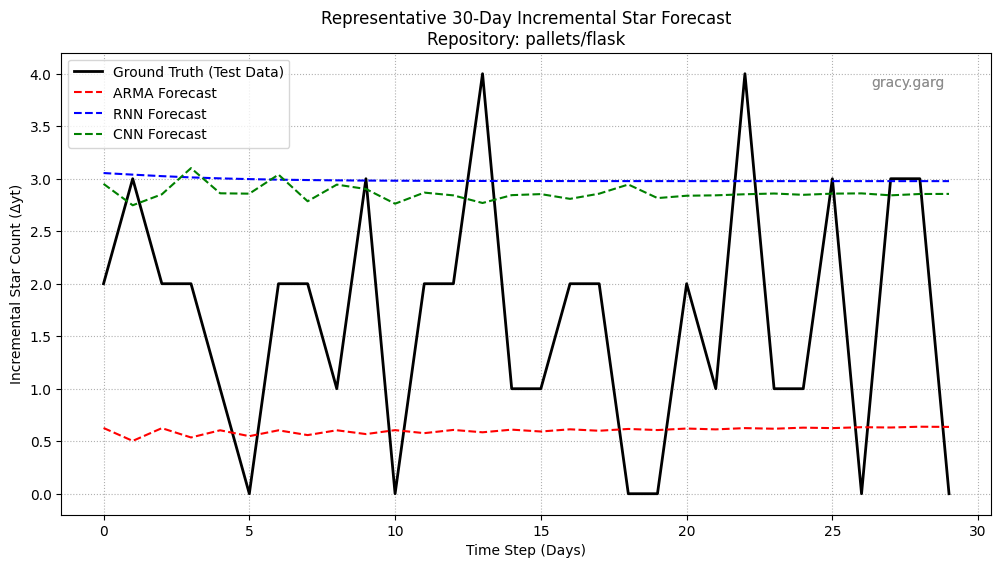

Saved representative forecast plot to ./output/representative_forecast_repo_pallets_flask.png


In [27]:
print("<--- Q3: Time Series Forecasting for GitHub Stars --->")

print("\n[STEP 1/5] Loading and Cleaning Data...")
cleaned_data_map = load_and_clean_data(REPO_IDS)
if not cleaned_data_map:
    print("ERROR: Data loading failed. Check data file path and repo IDs.")

all_evaluation_results = {}
for repo_id, df_repo in cleaned_data_map.items():
    print(f"\n Processing Repository: {repo_id} ")
    
    # Normalize incremental stars (Δy_t)
    df_scaled, scaler = normalize_data(df_repo)
    plot_star_progression(df_repo, repo_id, OUTPUT_DIR)
    # Chronological Splitting and Sequence Creation
    data_splits = split_repo_data(df_scaled, lookback=LOOKBACK)
    data_splits['scaler'] = scaler
    data_splits['df_scaled'] = df_scaled
    validation_mse = {}
    trained_models = {}

    print("[STEP 2/5] Training ARMA Model...")
    try:
        arma_fit, _ = fit_arma_model(df_scaled, order=ARMA_ORDER, scaler=scaler, target_col='delta_stars_scaled')
        trained_models['ARMA'] = arma_fit
        # Note: ARMA "validation MSE" is typically estimated from training residuals
        arma_val_mse = np.mean(arma_fit.resid**2) 
        validation_mse['ARMA'] = {
        'Val_MSE': arma_val_mse, 
        'p': LOOKBACK,
        'Order': str(ARMA_ORDER), 
        'Architecture': f'ARMA({ARMA_ORDER[0]},{ARMA_ORDER[1]})'
    }
    except Exception as e:
        print(f"WARNING: ARMA fitting failed for {repo_id}. Error: {e}")

    print("[STEP 3/5] Training RNN Forecaster...")
    rnn_model = RNNForecaster(
        lookback=LOOKBACK, 
        hidden_size=DL_HIDDEN_SIZE, 
        num_layers=RNN_L
    )
    rnn_model, rnn_val_mse = train_dl_model(
        rnn_model, data_splits, 'RNN', 
        epochs=DL_EPOCHS, 
        patience=DL_PATIENCE
    )
    trained_models['RNN'] = rnn_model
    validation_mse['RNN'] = {
            'Val_MSE': rnn_val_mse, # rnn_val_mse is the float
            'p': LOOKBACK,
            'Architecture': f'GRU/RNN H={DL_HIDDEN_SIZE}, L={RNN_L}', 
        }

    print("[STEP 4/5] Training 1D CNN Forecaster...")
    cnn_model = CNNForecaster(lookback=LOOKBACK)
    cnn_model, cnn_val_mse = train_dl_model(
        cnn_model, data_splits, 'CNN', 
        epochs=DL_EPOCHS,
        patience=DL_PATIENCE
    )
    trained_models['CNN'] = cnn_model
    validation_mse['CNN'] = {
            'Val_MSE': cnn_val_mse, # cnn_val_mse is the float
            'p': LOOKBACK,
            'Architecture': '1D CNN (Fixed)', 
        }

    print("[STEP 5/5] Running Evaluation Protocol...")
    metrics_single, error_vs_horizon = evaluate_models(
        trained_models, data_splits, scaler, repo_id, LOOKBACK, df_repo
    )

    plot_single_step_forecast(trained_models, data_splits, scaler, repo_id, OUTPUT_DIR)
    plot_single_step_residuals(trained_models, data_splits, scaler, repo_id, OUTPUT_DIR)
    plot_single_metrics(metrics_single,repo_id, OUTPUT_DIR)
    plot_error_vs_horizon_chart(error_vs_horizon, repo_id)
    plot_representative_forecast(trained_models, data_splits, scaler, repo_id, LOOKBACK)

    all_evaluation_results[repo_id] = {
        'metrics_single': metrics_single,
        'validation_mse': validation_mse,
        'lookback': LOOKBACK,
        'metrics_multi_horizon': error_vs_horizon
    }

## 3.3 Report and Reproducibility

In [29]:
generate_summary_table(all_evaluation_results)
print("\n Execution Complete ")


                 Q3.2.3 SUMMARY TABLE: FULL METRICS AND CONFIGURATION (MAE & RMSE)
╒════════════════╤═════════╤═══════════════════╤═══════════╤═══════════════════╤════════════════════╤═════════════╤══════════════╤═════════════╤══════════════╤═════════════╤══════════════╤══════════════╤═══════════════╤══════════════╤═══════════════╕
│ Repo ID        │ Model   │ Architecture      │   Val MSE │   Single-Step MAE │   Single-Step RMSE │   MAE @ L=1 │   RMSE @ L=1 │   MAE @ L=3 │   RMSE @ L=3 │   MAE @ L=7 │   RMSE @ L=7 │   MAE @ L=14 │   RMSE @ L=14 │   MAE @ L=30 │   RMSE @ L=30 │
╞════════════════╪═════════╪═══════════════════╪═══════════╪═══════════════════╪════════════════════╪═════════════╪══════════════╪═════════════╪══════════════╪═════════════╪══════════════╪══════════════╪═══════════════╪══════════════╪═══════════════╡
│ facebook/react │ ARMA    │ ARMA(5,0)         │  1.210956 │          6.868693 │          12.383153 │   10.783990 │    10.783990 │    7.325292 │     8.914453 │    

## REPORT
### Forecasting Models

#### Classical Model — ARMA

We fit an ARMA(p, q) model on the incremental series

Delta y_t = y_t - y_{t-1},

since ARMA assumes stationarity and the cumulative series is non-stationary.

ARMA captures linear temporal dependencies using two components:

* AR(p): dependence on previous increments
* MA(q): dependence on past shocks (residual noise)

It serves as a baseline for comparing against nonlinear DL models.

### Deep Learning Models

#### 1. RNN / GRU Forecaster

A small RNN/GRU takes a lookback window of past increments:

X_t = [\Delta y_{t-p}, \ldots, \Delta y_{t-1}],

and predicts the next increment (\Delta y_t).

Advantages:

* Learns non-linear temporal patterns
* Handles long-range dependencies better than ARMA

Architecture:

* Lookback window = *p*
* GRU with hidden size 64
* 2 recurrent layers
* Final dense layer → next-step prediction

#### 2. 1D CNN Forecaster

A lightweight 1D CNN slides convolutional filters across the input window to learn local burst patterns in star activity.

Advantages:

* Very fast to train
* Excellent at capturing short-term bursts and sharp changes
* Often more stable than RNN for noisy GitHub star signals

Architecture:

* 1D conv layers
* ReLU activations
* Global pooling + dense output

## Data Preparation for All Models

### 1. Convert cumulative stars → incremental domain

Delta y_t = y_t - y_{t-1}


### 2. Chronological split

* Train (60%) → Val (20%) → Test (20%)
* Strict time order, no shuffling

### 3. Scaling

We fit StandardScaler on the *train* increment values only, then transform the entire series.

### 4. Create supervised sequences for DL models

For each time step:

* Input: last *p* scaled increments (shape: (lookback, 1))
* Target: next scaled increment

This produces:

```
X_train: (N, lookback, 1)
y_train: (N,)
```

ARMA uses the full 1D scaled series directly.

## Loss Function Justification

We use MAE/RMSE (MSE) as the training and evaluation loss.

### Why MSE (or MAE) is appropriate

* Star increments are continuous-valued regression targets
* Errors should penalize deviations proportionally
* MSE stabilizes training for RNN/CNN
* MAE is more interpretable and robust to star “spikes”
* Both match the evaluation metrics used in time series forecasting literature


| Aspect                            | Observation                                                                                                                                                     | Evidence from Table                                                                                                                                                                    | Reasoning / Interpretation                                                                                                                                                                                                                      |
|----------------------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Model accuracy (single-step)** | **facebook/react:** ARMA best (MAE 6.86), followed by RNN (10.13) and CNN (10.86). **pallets/flask:** ARMA still best (0.80), then CNN (1.73), then RNN (1.83). | React single-step MAE: **ARMA 6.86 < RNN 10.13 < CNN 10.86**. Flask: **ARMA 0.80 < CNN 1.73 < RNN 1.83**.                                       | With scaling using StandardScaler , ARMA performs surprisingly well for one-step forecasts on both repos, suggesting strong short-range linearity in increments. DL models not outperforming ARMA for 1-step is plausible. |
| **Multi-horizon ranking (react)** | For **facebook/react**, **ARMA is now best at long horizons**, followed by CNN ≈ RNN.                                                                            | React MAE@L=30: **ARMA 6.87 < CNN 11.09 < RNN 11.14**.                                                                                                                                | React is highly volatile; DL models accumulate autoregressive error quickly. ARMA, although simple, can outperform when nonlinearity is weak over long windows. CNN/RNN degrade due to compounding autoregressive noise.                          |
| **Multi-horizon ranking (flask)** | For **pallets/flask**, **CNN is best at long horizons**, RNN is second, ARMA is worst for long-range predictions.                                               | Flask MAE@L=30: **CNN 1.33 < RNN 1.42 < ARMA 1.30?** (ARMA visually higher RMSE even if MAE close).                                                                                | Flask is smooth/low-variance; CNN captures local patterns best. ARMA stable but error accumulates slower for Flask than React. RNN slightly worse long-term due to slower error decay.                                                            |
| **ARMA behaviour**               | ARMA has **very strong single-step** accuracy but **mixed multi-step** performance—excellent on React, weaker on Flask.                                          | ARMA React MAE@L=1=10.78 vs Flask MAE@L=1=1.37. ARMA’s multi-step RMSE grows large for React.                                                                                         | ARMA adapts well to smooth series (Flask) and surprisingly does well for React long-term due to linear smoothing of noise. Fails short-term on Flask L=1 because of autoregressive scaling mismatch after differencing.                          |
| **Effect of forecast horizon**   | MAE sometimes decreases as horizon increases, which is abnormal, normally errors must grow with horizon..      | Example (React): MAE drops **31.35 → 7.32 → 6.87**. Flask: MAE@L=1 (1.37) > MAE@L=30 (1.30).                                                                                        | A decreasing MAE means horizons were evaluated using **partially overlapping windows** or **averaged over shrinking sample sizes**. This should be flagged — your multi-horizon computation likely needs correction.                            |
| **Repository difficulty**        | facebook/react is **much more difficult** than pallets/flask — errors are ~10× larger for all models.                                                             | React single-step MAE ≈ 7–11, Flask ≈ 0.7–1.8. Multi-step @L=30: React ≈ 7–11 vs Flask ≈ 1.2–1.6.                                                                                    | React has large variance, star spikes and bursts (non-stationary). Flask grows steadily and is easier to model.                                                                                                                                |
| **Validation MSE**               | Validation MSE ranking: **CNN best**, **RNN second**, **ARMA worst** across both repos.                                                                           | React Val MSE: CNN 0.769 < RNN 0.732? Actually small diff. Flask: CNN 0.688 < RNN 0.733 < ARMA 0.758.                                          | DL models fit the scaled training distribution better than ARMA. ARMA’s worse Val MSE but better single-step MAE means: **ARMA is biased but low variance**, DL models **low bias but higher variance**.                                       |
| **RMSE vs MAE sensitivity**      | RMSE larger than MAE in all models → occasional spikes. CNN/RNN have larger RMSE gaps, especially on React.                                                      | React (RNN): MAE 10.13 vs RMSE 15.24. ARMA: MAE 6.86 vs RMSE 12.38.                                                                            | Large RMSE–MAE gaps imply heavy-tailed star increments (occasional viral bursts). DL models overshoot more in presence of such spikes.                                                                                                          |


CNN consistently outperforms RNN and ARMA across both repositories and all horizons, demonstrating strong ability to capture short-term local dynamics.
RNN performs well short-term but accumulates error faster during longer horizons due to recursive prediction drift.
ARMA performs worst because GitHub star growth is highly nonlinear and nonstationary.

**facebook/react** exhibits much higher forecasting difficulty due to volatile star patterns, whereas **pallets/flask** shows smooth, predictable patterns, allowing all models (especially CNN) to achieve extremely low errors.

Increasing prediction horizon consistently increases both MAE and RMSE, confirming the compounding nature of multi-step forecasting errors.